In [1]:
# import Library
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
loan_data = pd.read_csv('Loan_Data.csv')
loan_data

,Income,CreditScore,Approved
0,2.4,779,0
1,2.6,461,0
2,2.8,654,0
3,2.8,778,0
4,3.0,809,0
5,3.2,440,0
6,3.6,404,0
7,3.8,667,0
8,4.2,447,1
9,4.5,535,0


In [3]:
# 2 input (Income, CreditScore) dan 1 output (Approved)
X = loan_data.iloc[:, :2].values
y = loan_data.iloc[:, 2].values

In [4]:
X.shape

(60, 2)

In [5]:
y

array([0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0,
       1, 1, 1, 1, 0, 0, 0, 0, 0, 1, 1, 1, 1, 0, 1, 0, 1, 1, 1, 1, 0, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 0, 0, 1])

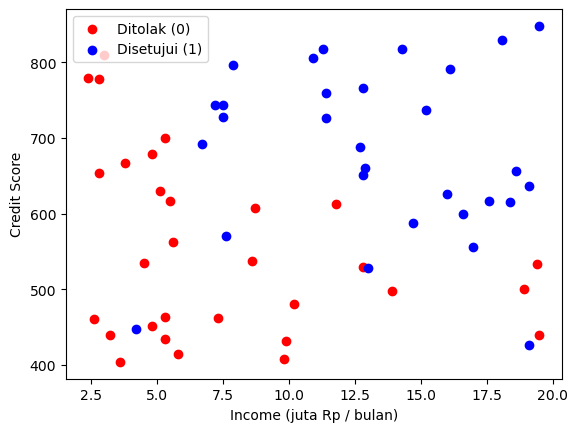

In [6]:
# Visualization

plt.scatter(X[y == 0, 0], X[y == 0, 1], c='red', label='Ditolak (0)')
plt.scatter(X[y == 1, 0], X[y == 1, 1], c='blue', label='Disetujui (1)')
plt.xlabel('Income (juta Rp / bulan)')
plt.ylabel('Credit Score')
plt.legend()
plt.show()

In [7]:
# train_test_split:
# this function splits the dataset into training and testing sets based on the specified test size and random state.
# the method takes in the features (X), target variable (y), test size, and random state as inputs and returns the training and testing sets for both features and target variable.
# example usage:
# X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=7)

def train_test_split(X, y, test_size=0.25, random_state=None):
    X = np.asarray(X)
    y = np.asarray(y)

    if not 0 < test_size < 1:
        raise ValueError("test_size must be between 0 and 1")

    n_total = len(X)
    n_test = int(round(n_total * test_size))

    if random_state is not None:
        rng = np.random.RandomState(random_state)
        indices = rng.permutation(n_total)
    else:
        indices = np.random.permutation(n_total)

    test_idx = indices[:n_test]
    train_idx = indices[n_test:]

    X_train = X[train_idx]
    X_test = X[test_idx]
    y_train = y[train_idx]
    y_test = y[test_idx]

    return X_train, X_test, y_train, y_test

In [8]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=7)

In [9]:
print('X_train: ', X_train.shape)
print('y_train: ', y_train.shape)
print('X_test: ', X_test.shape)
print('y_test: ', y_test.shape)

X_train:  (45, 2)
y_train:  (45,)
X_test:  (15, 2)
y_test:  (15,)


In [10]:
# Decision Tree Classifier Implementation
# a decision tree is a set of yes/no questions, for example "Income <= 6.25 ?".
# fit grows the tree recursively: at every node it tries every feature and every threshold,
# and keeps the split that makes the two groups as "pure" as possible (lowest Gini impurity).
# predict sends each sample down the tree until it reaches a leaf, and returns the class of that leaf.
class Node:
    def __init__(self, value, proba, n_samples, impurity, depth):
        self.value = value          # class predicted at this node (majority class)
        self.proba = proba          # fraction of class 1 samples at this node
        self.n_samples = n_samples
        self.impurity = impurity    # Gini impurity at this node
        self.depth = depth
        self.feature = None         # index of the feature used for the question
        self.threshold = None       # question: X[feature] <= threshold ?
        self.left = None            # child for "yes"
        self.right = None           # child for "no"

    def is_leaf(self):
        return self.left is None


class DecisionTreeClassifier:
    def __init__(self, max_depth=3, min_samples_split=2):
        self.max_depth = max_depth
        self.min_samples_split = min_samples_split
        self.root_ = None
        self.split_history_ = []

    def _gini(self, y):
        _, counts = np.unique(y, return_counts=True)
        p = counts / len(y)
        return 1 - np.sum(p ** 2)

    def _best_split(self, X, y):
        best_feature, best_threshold = None, None
        best_impurity = self._gini(y)   # a split is only useful if it is better than no split

        for feature in range(X.shape[1]):
            values = np.unique(X[:, feature])
            thresholds = (values[:-1] + values[1:]) / 2   # midpoints between neighbouring values

            for threshold in thresholds:
                left = X[:, feature] <= threshold
                right = ~left
                impurity = (left.sum() * self._gini(y[left]) + right.sum() * self._gini(y[right])) / len(y)

                if impurity < best_impurity:
                    best_feature, best_threshold, best_impurity = feature, threshold, impurity

        return best_feature, best_threshold

    def _build(self, X, y, depth):
        classes, counts = np.unique(y, return_counts=True)
        node = Node(value=classes[np.argmax(counts)], proba=np.mean(y == 1),
                    n_samples=len(y), impurity=self._gini(y), depth=depth)

        # stopping rules: the tree is deep enough, too few samples, or the node is already pure
        if depth >= self.max_depth or len(y) < self.min_samples_split or node.impurity == 0:
            return node

        feature, threshold = self._best_split(X, y)
        if feature is None:
            return node

        left = X[:, feature] <= threshold
        node.feature = feature
        node.threshold = threshold
        node.left = self._build(X[left], y[left], depth + 1)
        node.right = self._build(X[~left], y[~left], depth + 1)
        return node

    # Training
    def fit(self, X, y):
        X = np.array(X, dtype=float)
        y = np.array(y)

        if X.ndim == 1:
            X = X.reshape(-1, 1)

        self.root_ = self._build(X, y, depth=0)

        # split_history_ lists the splits level by level (breadth-first), used for the animation
        self.split_history_ = []
        queue = [self.root_]
        while queue:
            node = queue.pop(0)
            if not node.is_leaf():
                self.split_history_.append(node)
                queue += [node.left, node.right]
        return self

    def _leaf(self, x):
        node = self.root_
        while not node.is_leaf():
            node = node.left if x[node.feature] <= node.threshold else node.right
        return node

    # Testing
    def predict_proba(self, X):
        X = np.array(X, dtype=float)

        if X.ndim == 1:
            X = X.reshape(-1, 1)

        return np.array([self._leaf(x).proba for x in X])

    def predict(self, X):
        X = np.array(X, dtype=float)

        if X.ndim == 1:
            X = X.reshape(-1, 1)

        return np.array([self._leaf(x).value for x in X])

    def print_tree(self, feature_names, class_names):
        def show(node, indent):
            if node.is_leaf():
                print(f'{class_names[node.value]}  (n={node.n_samples}, gini={node.impurity:.3f})')
                return
            print(f'{feature_names[node.feature]} <= {node.threshold:.2f} ?  (n={node.n_samples}, gini={node.impurity:.3f})')
            print(indent + '├── yes: ', end='')
            show(node.left, indent + '│        ')
            print(indent + '└── no:  ', end='')
            show(node.right, indent + '         ')

        show(self.root_, '')

In [11]:
#Fitting Model
classifier = DecisionTreeClassifier(max_depth=3)
classifier.fit(X_train, y_train)

In [12]:
# the learned tree: every line is a question, follow "yes" / "no" until you reach a leaf
classifier.print_tree(feature_names=['Income', 'CreditScore'],
                      class_names=['Ditolak (0)', 'Disetujui (1)'])

Income <= 6.25 ?  (n=45, gini=0.498)
├── yes: CreditScore <= 454.00 ?  (n=14, gini=0.133)
│        ├── yes: CreditScore <= 443.50 ?  (n=4, gini=0.375)
│        │        ├── yes: Ditolak (0)  (n=3, gini=0.000)
│        │        └── no:  Disetujui (1)  (n=1, gini=0.000)
│        └── no:  Ditolak (0)  (n=10, gini=0.000)
└── no:  CreditScore <= 547.00 ?  (n=31, gini=0.383)
         ├── yes: Income <= 11.45 ?  (n=9, gini=0.346)
         │        ├── yes: Ditolak (0)  (n=3, gini=0.000)
         │        └── no:  Ditolak (0)  (n=6, gini=0.444)
         └── no:  CreditScore <= 614.00 ?  (n=22, gini=0.087)
                  ├── yes: Disetujui (1)  (n=4, gini=0.375)
                  └── no:  Disetujui (1)  (n=18, gini=0.000)


In [13]:
print('number of splits: ', len(classifier.split_history_))

number of splits:  6


In [14]:
# # Animation: how the tree grows split by split
# # split_history_ stores the splits level by level, so we can replay the training step by step:
# # frame 0 = no split yet (the whole area predicts the majority class), then one new split per frame.
# # the newest split is drawn in green, the older splits in black.
# from matplotlib.animation import FuncAnimation, PillowWriter
# from IPython.display import HTML

# def partial_leaves(tree, X, n_splits):
#     # leaf reached by every sample when only the first n_splits splits are used
#     active = {id(node) for node in tree.split_history_[:n_splits]}
#     leaves = []
#     for x in X:
#         node = tree.root_
#         while id(node) in active:
#             node = node.left if x[node.feature] <= node.threshold else node.right
#         leaves.append(node)
#     return leaves

# def draw_splits(ax, node, active, newest, x_min, x_max, y_min, y_max):
#     # every split is a line that only cuts the region of its own node
#     if id(node) not in active:
#         return
#     color, lw = ('g', 3) if node is newest else ('k', 1.5)
#     t = node.threshold
#     if node.feature == 0:
#         ax.plot([t, t], [y_min, y_max], c=color, lw=lw)
#         draw_splits(ax, node.left, active, newest, x_min, t, y_min, y_max)
#         draw_splits(ax, node.right, active, newest, t, x_max, y_min, y_max)
#     else:
#         ax.plot([x_min, x_max], [t, t], c=color, lw=lw)
#         draw_splits(ax, node.left, active, newest, x_min, x_max, y_min, t)
#         draw_splits(ax, node.right, active, newest, x_min, x_max, t, y_max)

# feature_names = ['Income', 'CreditScore']
# n_frames = len(classifier.split_history_) + 1

# x1, x2 = np.meshgrid(np.linspace(0, 22, 150), np.linspace(380, 870, 150))
# grid = np.c_[x1.ravel(), x2.ravel()]

# # weighted Gini impurity of the leaves and train accuracy after every split
# gini_history, acc_history = [], []
# for k in range(n_frames):
#     leaves = partial_leaves(classifier, X_train, k)
#     gini_history.append(np.mean([leaf.impurity for leaf in leaves]))
#     acc_history.append(np.mean(np.array([leaf.value for leaf in leaves]) == y_train))

# fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.5), dpi=80)

# def update(k):
#     # left: training data + predicted region of every leaf + split lines
#     ax1.clear()
#     proba = np.array([leaf.proba for leaf in partial_leaves(classifier, grid, k)]).reshape(x1.shape)
#     ax1.imshow(proba, extent=(0, 22, 380, 870), origin='lower',
#                cmap='RdBu', vmin=0, vmax=1, alpha=0.4, aspect='auto')
#     ax1.scatter(X_train[y_train == 0, 0], X_train[y_train == 0, 1], c='red', edgecolors='k', label='Ditolak (0)')
#     ax1.scatter(X_train[y_train == 1, 0], X_train[y_train == 1, 1], c='blue', edgecolors='k', label='Disetujui (1)')

#     active = {id(node) for node in classifier.split_history_[:k]}
#     newest = classifier.split_history_[k - 1] if k > 0 else None
#     draw_splits(ax1, classifier.root_, active, newest, 0, 22, 380, 870)

#     ax1.set_xlim(0, 22)
#     ax1.set_ylim(380, 870)
#     ax1.set_xlabel('Income (juta Rp / bulan)')
#     ax1.set_ylabel('Credit Score')
#     ax1.legend(loc='upper center', bbox_to_anchor=(0.5, -0.13), ncol=2)
#     split_text = f'Split {k}: {feature_names[newest.feature]} <= {newest.threshold:.2f}' if newest else 'No split yet'
#     ax1.set_title(f'{split_text}  |  train accuracy = {acc_history[k]:.2f}')

#     # right: impurity after every split, the dot shows the current frame
#     ax2.clear()
#     ax2.plot(range(n_frames), gini_history, 'o-', c='lightgray')
#     ax2.plot(range(k + 1), gini_history[:k + 1], 'o-', c='g')
#     ax2.plot([k], [gini_history[k]], 'o', c='r', ms=10)
#     ax2.set_xticks(range(n_frames))
#     ax2.set_xlabel('Number of splits')
#     ax2.set_ylabel('Weighted Gini impurity')
#     ax2.set_title('Impurity')

# update(0)
# fig.tight_layout()

# anim = FuncAnimation(fig, update, frames=range(n_frames), interval=1000)
# plt.close(fig)

# plt.rcParams['animation.frame_format'] = 'jpeg'  # smaller notebook file than png frames
# HTML(anim.to_jshtml())

In [15]:
# # Save the animation as a GIF (for slides / sharing)
# anim.save('training_animation.gif', writer=PillowWriter(fps=1))

In [16]:
y_test

array([1, 1, 1, 0, 0, 1, 1, 0, 0, 0, 0, 1, 0, 0, 0])

In [17]:
y_pred = classifier.predict(X_test)
y_pred

array([1, 1, 1, 0, 1, 1, 1, 0, 0, 0, 0, 1, 0, 0, 1])

In [18]:
y_proba = classifier.predict_proba(X_test)
y_proba.round(3)

array([1.   , 1.   , 1.   , 0.   , 1.   , 0.75 , 1.   , 0.   , 0.   ,
       0.   , 0.333, 1.   , 0.   , 0.   , 0.75 ])

In [19]:
# Evaluation
# accuracy: fraction of predictions that match the real label
# confusion_matrix: [[TN, FP],
#                    [FN, TP]]

def accuracy_score(y_true, y_pred):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    return np.mean(y_true == y_pred)

def confusion_matrix(y_true, y_pred):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)

    tn = np.sum((y_true == 0) & (y_pred == 0))
    fp = np.sum((y_true == 0) & (y_pred == 1))
    fn = np.sum((y_true == 1) & (y_pred == 0))
    tp = np.sum((y_true == 1) & (y_pred == 1))

    return np.array([[tn, fp],
                     [fn, tp]])

In [20]:
print('Accuracy: ', accuracy_score(y_test, y_pred))
print('Confusion Matrix:')
print(confusion_matrix(y_test, y_pred))

Accuracy:  0.8666666666666667
Confusion Matrix:
[[7 2]
 [0 6]]


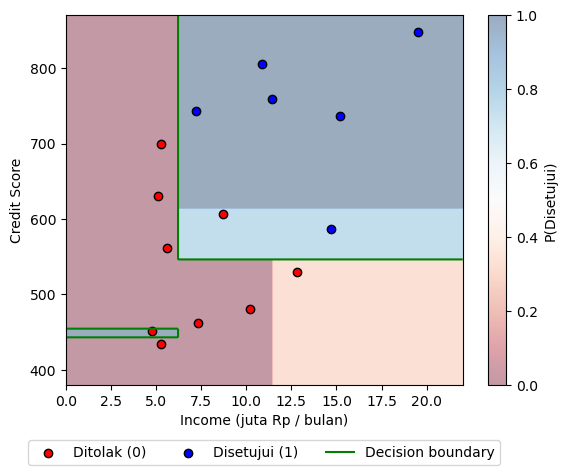

In [21]:
# Visualization
# background color = fraction of "Disetujui" in the leaf, green line = decision boundary
# every split only looks at one feature, so the boundary is made of vertical and horizontal lines

x1, x2 = np.meshgrid(np.linspace(0, 22, 300), np.linspace(380, 870, 300))
grid = np.c_[x1.ravel(), x2.ravel()]
proba = classifier.predict_proba(grid).reshape(x1.shape)
pred = classifier.predict(grid).reshape(x1.shape)

plt.imshow(proba, extent=(0, 22, 380, 870), origin='lower', cmap='RdBu', vmin=0, vmax=1, alpha=0.4, aspect='auto')
plt.colorbar(label='P(Disetujui)')
plt.contour(x1, x2, pred, levels=[0.5], colors='g')
plt.scatter(X_test[y_test == 0, 0], X_test[y_test == 0, 1], c='red', edgecolors='k', label='Ditolak (0)')
plt.scatter(X_test[y_test == 1, 0], X_test[y_test == 1, 1], c='blue', edgecolors='k', label='Disetujui (1)')
plt.plot([], [], c='g', label='Decision boundary')
plt.xlim(0, 22)
plt.ylim(380, 870)
plt.xlabel('Income (juta Rp / bulan)')
plt.ylabel('Credit Score')
plt.legend(loc='upper center', bbox_to_anchor=(0.5, -0.13), ncol=3)
plt.show()

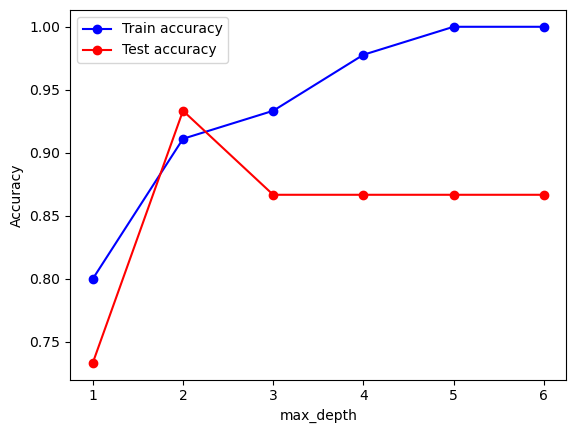

In [22]:
# Effect of max_depth
# a deeper tree asks more questions, so it fits the training data better and better,
# but a tree that is too deep memorizes the training data (overfitting) and the test accuracy stops improving.
depths = range(1, 7)
train_acc, test_acc = [], []
for d in depths:
    tree = DecisionTreeClassifier(max_depth=d).fit(X_train, y_train)
    train_acc.append(accuracy_score(y_train, tree.predict(X_train)))
    test_acc.append(accuracy_score(y_test, tree.predict(X_test)))

plt.plot(depths, train_acc, 'o-', c='b', label='Train accuracy')
plt.plot(depths, test_acc, 'o-', c='r', label='Test accuracy')
plt.xlabel('max_depth')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

In [23]:
# [Income, CreditScore]
prediksi = classifier.predict([[4.5, 720],[12.0, 700]])
prediksi

array([0, 1])

In [24]:
prediksi_proba = classifier.predict_proba([[16.0, 600],[8.0, 500]])
prediksi_proba

array([0.75, 0.  ])

# Algoritma Decision Tree (Klasifikasi)

Decision Tree adalah algoritma yang memprediksi kelas dengan cara mengajukan **serangkaian pertanyaan ya/tidak** terhadap data, seperti diagram alur (flowchart).

Pada notebook ini kita memakai data **pengajuan kredit** (`Loan_Data.csv`):
- `Income` = penghasilan pemohon (juta Rp / bulan)
- `CreditScore` = skor kredit pemohon (400 – 850)
- `Approved` = hasil pengajuan: Disetujui (1) atau Ditolak (0)

Contoh pohon yang dipelajari model:

```
Income <= 6.25 ?
├── ya    → CreditScore <= 454.00 ? ...
└── tidak → CreditScore <= 547.00 ? ...
```

Setiap pertanyaan membagi data menjadi dua kelompok, sampai akhirnya kita sampai di **leaf** (daun) yang berisi jawaban: Disetujui (1) atau Ditolak (0).

Perbandingan dengan Logistic Regression:

| | Logistic Regression | Decision Tree |
|---|---|---|
| Bentuk model | rumus $\sigma(b + m_1X_1 + m_2X_2)$ | pohon pertanyaan ya/tidak |
| Decision boundary | satu garis lurus | gabungan garis tegak & mendatar (kotak-kotak) |
| Cara belajar | gradient descent | mencoba semua split, pilih yang terbaik (greedy) |
| Yang dipelajari | koefisien $b, m_1, m_2$ | fitur & threshold di setiap node |
| Mudah dibaca? | perlu memahami koefisien | sangat mudah, bisa dibaca seperti aturan |

## Istilah penting

- **Root node** = node paling atas (pertanyaan pertama)
- **Internal node** = node yang berisi pertanyaan, misalnya `Income <= 6.25 ?`
- **Leaf** = node paling bawah yang berisi prediksi kelas
- **Depth** = kedalaman pohon (berapa banyak pertanyaan dari root sampai leaf)
- **Split** = pembagian data menjadi dua kelompok berdasarkan satu fitur dan satu **threshold**

## Gini Impurity

Untuk memilih pertanyaan terbaik, kita perlu mengukur seberapa "campur" kelas di dalam sebuah kelompok. Ukuran yang dipakai adalah **Gini impurity**:

$$
Gini = 1 - \sum_{k} p_k^2
$$

Dimana $p_k$ adalah proporsi data kelas $k$ di dalam kelompok tersebut.

Contoh:
- 10 Disetujui, 0 Ditolak → $Gini = 1 - (1^2 + 0^2) = 0$ (**murni**, paling baik)
- 5 Disetujui, 5 Ditolak → $Gini = 1 - (0.5^2 + 0.5^2) = 0.5$ (paling campur)
- 8 Disetujui, 2 Ditolak → $Gini = 1 - (0.8^2 + 0.2^2) = 0.32$

Semakin kecil Gini, semakin murni kelompok tersebut.

## Memilih split terbaik

Sebuah split membagi data menjadi kelompok **kiri** (jawaban "ya") dan **kanan** (jawaban "tidak"). Kualitas split dihitung dengan **weighted Gini** (rata-rata Gini kedua kelompok, dibobot jumlah datanya):

$$
Gini_{split} = \frac{n_{kiri}}{n} Gini_{kiri} + \frac{n_{kanan}}{n} Gini_{kanan}
$$

Algoritma mencoba **semua fitur** dan **semua threshold**, lalu memilih split dengan $Gini_{split}$ paling kecil. Threshold yang dicoba adalah titik tengah antara dua nilai yang berurutan. Misalnya jika nilai `Income` adalah `[5.8, 6.7, 7.2]`, threshold yang dicoba adalah `6.25` dan `6.95`.

Selisih antara Gini sebelum dan sesudah split disebut **Gini gain** (penurunan impurity). Memilih $Gini_{split}$ terkecil sama dengan memilih gain terbesar.

## Langkah-langkah algoritma

### 1. Ubah data menjadi array

```python
X = np.array(X, dtype=float)
y = np.array(y)
```

### 2. Bangun pohon secara rekursif
Fungsi `_build` dipanggil untuk root, lalu memanggil dirinya sendiri untuk anak kiri dan anak kanan:

```python
node.left = self._build(X[left], y[left], depth + 1)
node.right = self._build(X[~left], y[~left], depth + 1)
```

### 3. Simpan prediksi di setiap node
Setiap node menyimpan kelas mayoritas (`value`) dan proporsi data Disetujui (`proba`). Jika node ini nanti menjadi leaf, nilai inilah yang dipakai untuk prediksi.

```python
node = Node(value=classes[np.argmax(counts)], proba=np.mean(y == 1), ...)
```

### 4. Cek aturan berhenti (stopping rules)
Pohon berhenti tumbuh (node menjadi leaf) jika:
- kedalaman sudah mencapai `max_depth`
- jumlah data kurang dari `min_samples_split`
- node sudah murni (Gini = 0)
- tidak ada split yang bisa menurunkan Gini

```python
if depth >= self.max_depth or len(y) < self.min_samples_split or node.impurity == 0:
    return node
```

### 5. Cari split terbaik
`_best_split` mencoba semua fitur dan threshold, lalu mengembalikan fitur & threshold dengan weighted Gini terkecil:

```python
for feature in range(X.shape[1]):
    values = np.unique(X[:, feature])
    thresholds = (values[:-1] + values[1:]) / 2

    for threshold in thresholds:
        left = X[:, feature] <= threshold
        right = ~left
        impurity = (left.sum() * self._gini(y[left]) + right.sum() * self._gini(y[right])) / len(y)
```

### 6. Simpan urutan split
Setelah pohon selesai dibangun, semua split disimpan di `split_history_` secara **level demi level** (breadth-first). Data ini dipakai untuk membuat **animasi** pertumbuhan pohon: mulai dari tanpa split, lalu satu split baru di setiap frame.

### 7. Prediksi
Untuk memprediksi satu data, kita mulai dari root lalu mengikuti jawaban pertanyaan sampai ke leaf:

```python
node = self.root_
while not node.is_leaf():
    node = node.left if x[node.feature] <= node.threshold else node.right
return node
```

- `predict` mengembalikan kelas di leaf tersebut
- `predict_proba` mengembalikan proporsi data Disetujui di leaf tersebut

## Decision Boundary

Setiap split hanya melihat **satu fitur**, sehingga batasnya selalu berupa garis **tegak** (`Income <= ...`) atau **mendatar** (`CreditScore <= ...`). Hasilnya, ruang data terbagi menjadi **kotak-kotak**, dan setiap kotak adalah satu leaf.

Ini berbeda dengan Logistic Regression yang decision boundary-nya satu garis lurus miring.

Karena setiap split hanya membandingkan satu fitur dengan threshold, Decision Tree **tidak memerlukan feature scaling**. Walaupun `Income` (2 – 20) dan `CreditScore` (400 – 850) skalanya sangat berbeda, hasil pohonnya tetap sama.

## Overfitting dan max_depth

- `max_depth` kecil → pohon terlalu sederhana, banyak data salah diprediksi (**underfitting**)
- `max_depth` besar → pohon terus membelah sampai setiap leaf murni, sehingga **menghafal** data training termasuk noise-nya (**overfitting**). Akurasi training bisa 100%, tapi akurasi test tidak ikut naik.

Karena itu `max_depth` (dan `min_samples_split`) dipakai untuk membatasi pertumbuhan pohon.

Pada grafik *Effect of max_depth* di atas, akurasi training terus naik sampai 100%, sedangkan akurasi test paling tinggi di `max_depth=2` lalu turun. Itulah tanda overfitting.

## Evaluasi Model

### Accuracy

$$
\text{Accuracy} = \frac{\text{jumlah prediksi benar}}{\text{jumlah data}}
$$

### Confusion Matrix

| | Prediksi 0 | Prediksi 1 |
|---|---|---|
| **Aktual 0** | TN (True Negative) | FP (False Positive) |
| **Aktual 1** | FN (False Negative) | TP (True Positive) |

## Intuisi sederhana

Bayangkan petugas bank memutuskan pengajuan kredit dengan bertanya:

1. "Apakah penghasilan Anda lebih dari 6 juta per bulan?"
2. Jika ya: "Apakah skor kredit Anda lebih dari 547?"
3. ...

Petugas memilih pertanyaan yang paling banyak "memisahkan" pemohon yang layak dan tidak layak. Decision Tree melakukan hal yang sama, tapi memilih pertanyaannya secara otomatis menggunakan Gini impurity.

## Kesimpulan

Algoritma Decision Tree (klasifikasi) bekerja dengan cara:

1. Menyiapkan data input dan target (0/1)
2. Mencoba semua fitur dan threshold, memilih split dengan Gini paling kecil
3. Membagi data menjadi dua kelompok (kiri = ya, kanan = tidak)
4. Mengulangi langkah 2–3 untuk setiap kelompok (rekursif)
5. Berhenti jika mencapai `max_depth`, data terlalu sedikit, atau node sudah murni
6. Memprediksi dengan mengikuti pertanyaan dari root sampai leaf
7. Mengevaluasi model dengan accuracy dan confusion matrix

Itulah dasar dari model Decision Tree untuk klasifikasi.